# Statistical analysis of the research questions

**Incremental Predictive Value of Two Antenatal Visits for Recorded Low Birth Weight: A Retrospective Cohort Study.** Kelvin Rwihimba, BSc Software Engineering, African Leadership University. Supervisor: Emmanuel Adjei.

**What this notebook does.** It answers research questions 1 to 4 with estimates, 95 percent intervals and p values, from predictions already saved in `outputs/`. It never fits a model and never changes the served artefact. The tested calculations live in `src/antenatal/research.py` and are run by `python -m antenatal research-results`; this notebook reads what that command wrote and checks it.

**Terms.** *Average precision* is the area under the precision recall curve without interpolation; a model that ranks at random scores the share of births that are low birth weight. *ROC AUC* is the area under the receiver operating characteristic curve, the chance that a random low birth weight pregnancy is ranked above a random other one. A *paired group bootstrap* redraws whole registration groups (records sharing age, last menstrual date, height, weight and prior deliveries) with replacement and recomputes the difference between two models on the same draw. The *bootstrap p value* is twice the smaller share of draws on either side of zero. The *Holm adjustment* raises p values in a family of tests so that the chance of any false finding in the family stays at 5 percent.

**What is not here.** The held out records are not read. Section 4 is a template that fills itself only after the single held out evaluation has run under `docs/holdout_protocol.md`.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from antenatal.config import PRIMARY
from antenatal.evaluation.delong import delong_paired
from antenatal.paths import ProjectPaths
from antenatal.research import check_alignment, load_all, questions_table

paths = ProjectPaths.from_root(Path.cwd().parent)
research = paths.outputs / "research"
if not (research / "results_table.csv").exists():
    from antenatal.reporting.research_report import write_research_results
    write_research_results(paths)

pd.set_option("display.width", 160)
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 70)
table = lambda name: pd.read_csv(paths.tables / f"{name}.csv")
results = pd.read_csv(research / "results_table.csv")
print("Seed", PRIMARY.seed, "| bootstrap resamples", PRIMARY.bootstrap_resamples,
      "| repeats", PRIMARY.repeats, "| outer folds", PRIMARY.outer_folds)

Seed 20260930 | bootstrap resamples 2000 | repeats 10 | outer folds 5


## 1. The research questions

The four questions are quoted from the proposal. Each is mapped to its endpoint, method and hypothesis. The prespecified primary hypothesis (question 1) and the prespecified secondary hypothesis (set B over set A on ROC AUC) are not adjusted for multiple testing. Every other tested row forms one exploratory family with a Holm adjustment. Calibration slope and intercept differences are shown with intervals but not tested. Question 4 also reads saved sensitivity analyses on other cohorts; their predictions are not stored, so their p values use the normal approximation with the saved bootstrap standard error.

In [2]:
questions_table()

,number,question,endpoint,method,null_hypothesis
0,1,Do measurements from the first antenatal visit improve prediction ...,Average precision of set C minus set B,"Paired group bootstrap, both model families; the prespecified prim...",Adding first visit values changes average precision by zero
1,2,"Does a learned model outperform constant prevalence prediction, an...","Average precision of sets A, B and C minus the prevalence only mod...",Paired group bootstrap; DeLong's test beside each ROC AUC as descr...,Each difference is zero
2,3,"Optionally, within fixed ranking budgets, what proportion of pregn...","Share of events in the top 10, 20 and 30 percent of the served ran...",Group bootstrap of retrieval minus the random expectation,The served ranking retrieves no more than random
3,4,What sensitivity do the feature set comparisons show to missing me...,"The primary comparison, C minus B average precision, under each se...",Paired group bootstrap; saved sensitivity analyses use the normal ...,Each difference is zero


## 2. Per model performance on development records

Pooled results first: the out of fold probability of each record is averaged over the ten repeats and every metric is computed once over all 3,126 development records, with its own group bootstrap interval. Fold level results come after and are only descriptive; no test is made over folds, because folds share training records and are not independent.

In [3]:
performance = table("model_performance")
counts = performance[["n", "events"]].iloc[0]
print(f"Development records {counts['n']:,}, events {counts['events']}, "
      f"prevalence {counts['events'] / counts['n']:.4f}")
performance.pivot_table(index=["model", "feature_set"], columns="metric",
                        values=["value", "ci_low", "ci_high"]).round(4)

Development records 3,126, events 165, prevalence 0.0528


ci_high          ci_low           value        
metric                                 pr_auc roc_auc  pr_auc roc_auc  pr_auc roc_auc
model                     feature_set                                                
baseline_prevalence       A            0.0654  0.5562  0.0453  0.4671  0.0542  0.5121
decision_tree             C            0.0930  0.6536  0.0598  0.5662  0.0728  0.6108
gradient_boosting         A            0.1163  0.6655  0.0690  0.5757  0.0877  0.6193
                          B            0.1267  0.6974  0.0744  0.6099  0.0943  0.6538
                          C            0.1172  0.6829  0.0696  0.5929  0.0877  0.6387
gradient_boosting_uniform A            0.1131  0.6603  0.0667  0.5693  0.0841  0.6139
                          B            0.1260  0.7000  0.0741  0.6139  0.0935  0.6570
                          C            0.1119  0.6855  0.0689  0.5995  0.0861  0.6432
knn                       C            0.0961  0.6309  0.0583  0.5369  0.0730  0.5830
lda                       C            0.1123  0.6754  0.0683  0.5855  0.0864  0.6292
logistic_l1               C            0.1130  0.6687  0.0685  0.5764  0.0862  0.6209
logistic_l2               A            0.1190  0.6593  0.0687  0.5641  0.0880  0.6113
                          B            0.1252  0.6794  0.0726  0.5863  0.0933  0.6318
                          C            0.1178  0.6746  0.0703  0.5844  0.0894  0.6281
naive_bayes               C            0.0900  0.6246  0.0554  0.5330  0.0693  0.5783
random_forest             C            0.1233  0.6904  0.0723  0.6043  0.0916  0.6488

In [4]:
calibration = table("calibration_by_set")
calibration.round(3)

,model,feature_set,n,events,calibration_slope,calibration_slope_low,calibration_slope_high,calibration_intercept,calibration_intercept_low,calibration_intercept_high
0,logistic_l2,A,3126,165,1.209,0.644,1.823,-0.000,-0.169,0.154
1,logistic_l2,B,3126,165,1.011,0.639,1.415,-0.000,-0.168,0.152
2,logistic_l2,C,3126,165,0.979,0.627,1.368,-0.002,-0.167,0.150
3,gradient_boosting,A,3126,165,0.920,0.614,1.252,-0.006,-0.173,0.146
4,gradient_boosting,B,3126,165,1.144,0.803,1.477,0.001,-0.164,0.154
5,gradient_boosting,C,3126,165,1.161,0.791,1.529,0.003,-0.162,0.156


In [5]:
summary = table("summary_by_experiment")
summary[["model", "feature_set", "pr_auc", "roc_auc", "brier",
         "calibration_slope", "calibration_intercept"]].round(4)

,model,feature_set,pr_auc,roc_auc,brier,calibration_slope,calibration_intercept
0,baseline_prevalence,A,0.0542,0.5121,0.0500,-39.8883,-0.0000e+00
1,decision_tree,C,0.0728,0.6108,0.0499,0.6366,7.2000e-03
2,gradient_boosting,A,0.0877,0.6193,0.0494,0.9200,-6.4000e-03
3,gradient_boosting,B,0.0943,0.6538,0.0493,1.1438,1.3000e-03
4,gradient_boosting,C,0.0877,0.6387,0.0494,1.1613,3.2000e-03
5,gradient_boosting_uniform,A,0.0841,0.6139,0.0495,0.9466,-7.0000e-03
6,gradient_boosting_uniform,B,0.0935,0.6570,0.0493,1.1811,9.0000e-04
7,gradient_boosting_uniform,C,0.0861,0.6432,0.0494,1.1255,2.1000e-03
8,knn,C,0.0730,0.5830,0.0499,0.4417,4.0800e-02
9,lda,C,0.0864,0.6292,0.0499,0.5966,-3.0600e-02


In [6]:
folds = table("cv_fold_metrics")
fold_summary = (folds.groupby(["model", "feature_set"])[["pr_auc", "roc_auc", "brier"]]
                .agg(["mean", "std"]).round(4))
print("Fold level, descriptive only:", len(folds), "fold results")
fold_summary

Fold level, descriptive only: 800 fold results


pr_auc         roc_auc           brier        
                                         mean     std    mean     std    mean     std
model                     feature_set                                                
baseline_prevalence       A            0.0528  0.0000  0.5000  0.0000  0.0500  0.0000
decision_tree             C            0.0676  0.0105  0.5659  0.0503  0.0514  0.0011
gradient_boosting         A            0.0973  0.0220  0.6128  0.0433  0.0497  0.0007
                          B            0.0983  0.0242  0.6339  0.0436  0.0496  0.0006
                          C            0.0927  0.0178  0.6205  0.0452  0.0497  0.0004
gradient_boosting_uniform A            0.0941  0.0226  0.6085  0.0439  0.0497  0.0006
                          B            0.1021  0.0212  0.6404  0.0432  0.0495  0.0005
                          C            0.0934  0.0223  0.6273  0.0442  0.0497  0.0006
knn                       C            0.0762  0.0154  0.5752  0.0441  0.0502  0.0007
lda                       C            0.0992  0.0222  0.6287  0.0432  0.0501  0.0011
logistic_l1               C            0.0991  0.0233  0.6192  0.0452  0.0496  0.0005
logistic_l2               A            0.1074  0.0279  0.6128  0.0497  0.0496  0.0003
                          B            0.1107  0.0286  0.6321  0.0441  0.0494  0.0004
                          C            0.1013  0.0234  0.6271  0.0423  0.0495  0.0004
naive_bayes               C            0.0825  0.0191  0.6143  0.0517  0.9245  0.0104
random_forest             C            0.1057  0.0282  0.6461  0.0398  0.0494  0.0003

Operating points at the ranking budgets, retrieval within each budget, and net benefit from the decision curve, for the served configuration (logistic regression on set C):

In [7]:
points = table("operating_points_v2")
display(points[(points["model"] == "logistic_l2") & (points["feature_set"] == "C")].round(4))
display(table("retrieval_at_budget").round(4))
net = table("net_benefit_v2")
net[["threshold", "act for everyone", "logistic_l2 on B", "logistic_l2 on C"]].round(4)

,model,feature_set,operating_point,tp,fp,fn,tn,sensitivity,specificity,ppv,npv,f1
8,logistic_l2,C,top 10 percent,36,277,129,2684,0.2182,0.9065,0.1150,0.9541,0.1506
9,logistic_l2,C,top 20 percent,57,569,108,2392,0.3455,0.8078,0.0911,0.9568,0.1441
10,logistic_l2,C,top 30 percent,79,859,86,2102,0.4788,0.7099,0.0842,0.9607,0.1432
11,logistic_l2,C,probability at least 0.0528,99,1251,66,1710,0.6000,0.5775,0.0733,0.9628,0.1307


,model,budget_percent,pregnancies_in_budget,events_found,events_total,retrieval,ci_low,ci_high,random_expectation,ratio_to_random,n
0,"logistic_l2, set C",10,313,36,165,0.2182,0.1585,0.2792,0.1,2.1818,3126
1,"logistic_l2, set C",20,626,57,165,0.3455,0.2781,0.4204,0.2,1.7273,3126
2,"logistic_l2, set C",30,938,79,165,0.4788,0.4041,0.5537,0.3,1.5960,3126


,threshold,act for everyone,logistic_l2 on B,logistic_l2 on C
0,0.03,0.0235,0.0232,0.0240
1,0.04,0.0133,0.0167,0.0154
2,0.05,0.0029,0.0121,0.0113
3,0.06,-0.0077,0.0083,0.0075
4,0.07,-0.0185,0.0052,0.0043
5,0.08,-0.0296,0.0040,0.0036
6,0.09,-0.0409,0.0021,0.0027
7,0.10,-0.0525,0.0020,0.0016
8,0.11,-0.0643,0.0020,0.0018
9,0.12,-0.0764,0.0010,0.0010


## 3. Comparisons

Before any paired test the predictions of both models must cover exactly the same development records. The check below loads the saved predictions and refuses a misaligned pair.

In [8]:
saved = load_all(paths)
keys = {("logistic_l2", s) for s in "ABC"} | {("gradient_boosting", s) for s in "ABC"}
keys |= {("logistic_l2_no_indicator", s) for s in "BC"} | {("baseline_prevalence", "A")}
for key in sorted(keys):
    check_alignment(saved, key)
print("Aligned on", len(saved.development), "development records:", len(keys), "prediction sets")

Aligned on 3126 development records: 9 prediction sets


The full table of tested and descriptive rows written by `python -m antenatal research-results`:

In [9]:
columns = ["question", "model", "comparison", "n", "events", "metric", "family", "difference",
           "ci_low", "ci_high", "p_value", "p_method", "p_holm", "delong_p_value"]
results[columns]

,question,model,comparison,n,events,metric,family,difference,ci_low,ci_high,p_value,p_method,p_holm,delong_p_value
0,1,logistic_l2,C over B (first visit added),3126,165,pr_auc,"prespecified, not adjusted",-3.9599e-03,-1.3020e-02,0.0025,0.2300,paired group bootstrap,NaN,NaN
1,2,logistic_l2,C over B (first visit added),3126,165,roc_auc,"exploratory, Holm",-3.7641e-03,-1.3830e-02,0.0060,0.4500,paired group bootstrap,1.000,4.4477e-01
2,secondary hypothesis,logistic_l2,B over A (second visit added),3126,165,pr_auc,"descriptive, not tested",5.3159e-03,-1.1156e-02,0.0227,0.5390,paired group bootstrap,NaN,NaN
3,secondary hypothesis,logistic_l2,B over A (second visit added),3126,165,roc_auc,"prespecified, not adjusted",2.0487e-02,-6.6088e-03,0.0476,0.1370,paired group bootstrap,NaN,1.3115e-01
4,supporting,logistic_l2,C over A (both visits added),3126,165,pr_auc,"exploratory, Holm",1.3560e-03,-1.6459e-02,0.0170,0.9380,paired group bootstrap,1.000,NaN
5,supporting,logistic_l2,C over A (both visits added),3126,165,roc_auc,"descriptive, not tested",1.6722e-02,-1.1392e-02,0.0458,0.2520,paired group bootstrap,NaN,2.6064e-01
6,2,logistic_l2,A over B0 (registration over prevalence),3126,165,pr_auc,"exploratory, Holm",3.3796e-02,1.6174e-02,0.0625,0.0000,paired group bootstrap,0.000,NaN
7,2,logistic_l2,A over B0 (registration over prevalence),3126,165,roc_auc,"descriptive, not tested",9.9245e-02,3.1381e-02,0.1657,0.0060,paired group bootstrap,NaN,3.5335e-03
8,2,logistic_l2,B over B0,3126,165,pr_auc,"exploratory, Holm",3.9112e-02,2.0541e-02,0.0690,0.0000,paired group bootstrap,0.000,NaN
9,2,logistic_l2,B over B0,3126,165,roc_auc,"descriptive, not tested",1.1973e-01,5.5250e-02,0.1827,0.0000,paired group bootstrap,NaN,2.4135e-04


DeLong's test is recomputed here for the secondary comparison to show it matches the table. It treats records as independent, which records in the same registration group are not, so it is descriptive only:

In [10]:
for model in ("logistic_l2", "gradient_boosting"):
    check = delong_paired(saved.y, saved.averaged(model, "B"), saved.averaged(model, "A"))
    row = results[(results["model"] == model) & (results["metric"] == "roc_auc")
                  & results["comparison"].str.startswith("B over A (")].iloc[0]
    assert abs(check.p_value - row["delong_p_value"]) < 1e-12
    print(f"{model}: B minus A ROC AUC {check.difference:+.4f}, DeLong p {check.p_value:.3f}, "
          f"bootstrap p {row['p_value']:.3f}")

logistic_l2: B minus A ROC AUC +0.0205, DeLong p 0.131, bootstrap p 0.137
gradient_boosting: B minus A ROC AUC +0.0345, DeLong p 0.015, bootstrap p 0.008


What each research question finds, printed from the table:

In [11]:
names = {"pr_auc": "average precision", "roc_auc": "ROC AUC", "brier": "Brier score",
         "retrieval_gain": "retrieval minus random"}

def sentence(r):
    span = f"{r['difference']:+.4f} (95% interval {r['ci_low']:+.4f} to {r['ci_high']:+.4f})"
    p = r["p_holm"] if pd.notna(r["p_holm"]) else r["p_value"]
    label = "Holm adjusted p" if pd.notna(r["p_holm"]) else "p"
    shown = "below 0.001" if p < 0.001 else f"{p:.3f}"
    verdict = "excludes zero" if r["excludes_zero"] else "contains zero"
    return f"* Question {r['question']}, {r['model']}, {r['comparison']}, {names.get(r['metric'], r['metric'])}: {span}, {label} {shown}; the interval {verdict}."

tested = results[results["family"] != "descriptive, not tested"]
display(Markdown("\n".join(sentence(r) for _, r in tested[tested["question"].isin(["1", "2", "3", "4"])].iterrows())))

* Question 1, logistic_l2, C over B (first visit added), average precision: -0.0040 (95% interval -0.0130 to +0.0025), p 0.230; the interval contains zero.
* Question 2, logistic_l2, C over B (first visit added), ROC AUC: -0.0038 (95% interval -0.0138 to +0.0060), Holm adjusted p 1.000; the interval contains zero.
* Question 2, logistic_l2, A over B0 (registration over prevalence), average precision: +0.0338 (95% interval +0.0162 to +0.0625), Holm adjusted p below 0.001; the interval excludes zero.
* Question 2, logistic_l2, B over B0, average precision: +0.0391 (95% interval +0.0205 to +0.0690), Holm adjusted p below 0.001; the interval excludes zero.
* Question 2, logistic_l2, C over B0, average precision: +0.0352 (95% interval +0.0173 to +0.0621), Holm adjusted p below 0.001; the interval excludes zero.
* Question 1, gradient_boosting, C over B (first visit added), average precision: -0.0066 (95% interval -0.0173 to +0.0024), p 0.143; the interval contains zero.
* Question 2, gradient_boosting, C over B (first visit added), ROC AUC: -0.0151 (95% interval -0.0305 to -0.0002), Holm adjusted p 0.736; the interval excludes zero.
* Question 2, gradient_boosting, A over B0 (registration over prevalence), average precision: +0.0334 (95% interval +0.0161 to +0.0598), Holm adjusted p below 0.001; the interval excludes zero.
* Question 2, gradient_boosting, B over B0, average precision: +0.0401 (95% interval +0.0221 to +0.0707), Holm adjusted p below 0.001; the interval excludes zero.
* Question 2, gradient_boosting, C over B0, average precision: +0.0335 (95% interval +0.0174 to +0.0601), Holm adjusted p below 0.001; the interval excludes zero.
* Question 4, logistic_l2, Indicators added, set B, average precision: +0.0029 (95% interval -0.0088 to +0.0147), Holm adjusted p 1.000; the interval contains zero.
* Question 4, logistic_l2, Indicators added, set C, average precision: +0.0022 (95% interval -0.0069 to +0.0114), Holm adjusted p 1.000; the interval contains zero.
* Question 2, logistic_l2, C over B (first visit added), Brier score: +0.0000 (95% interval -0.0001 to +0.0002), Holm adjusted p 1.000; the interval contains zero.
* Question 2, gradient_boosting, C over B (first visit added), Brier score: +0.0002 (95% interval -0.0000 to +0.0003), Holm adjusted p 1.000; the interval contains zero.
* Question 3, logistic_l2, Top 10 percent, set C over random ranking, retrieval minus random: +0.1182 (95% interval +0.0585 to +0.1792), Holm adjusted p below 0.001; the interval excludes zero.
* Question 3, logistic_l2, Top 20 percent, set C over random ranking, retrieval minus random: +0.1455 (95% interval +0.0781 to +0.2204), Holm adjusted p below 0.001; the interval excludes zero.
* Question 3, logistic_l2, Top 30 percent, set C over random ranking, retrieval minus random: +0.1788 (95% interval +0.1041 to +0.2537), Holm adjusted p below 0.001; the interval excludes zero.
* Question 4, logistic_l2, Every screened measurement recorded at both visits: C over B, average precision: -0.0010 (95% interval -0.0067 to +0.0046), Holm adjusted p 1.000; the interval contains zero.
* Question 4, logistic_l2_iterative_pooled, Iterative imputation, five draws pooled: C over B, average precision: -0.0055 (95% interval -0.0151 to +0.0008), Holm adjusted p 1.000; the interval contains zero.
* Question 4, gradient_boosting_uniform, Gradient boosted trees with median imputation and indicators: C over B, average precision: -0.0074 (95% interval -0.0216 to +0.0008), Holm adjusted p 1.000; the interval contains zero.
* Question 4, logistic_l2, Excluding records marked both term and preterm: C over B, average precision: -0.0023 (95% interval -0.0114 to +0.0042), Holm adjusted p 1.000; the interval contains zero.
* Question 4, logistic_l2, Lower birth weight bound relaxed to 0.5 kg: C over B, average precision: -0.0040 (95% interval -0.0130 to +0.0025), Holm adjusted p 1.000; the interval contains zero.
* Question 4, logistic_l2, Visit two by 24 weeks: C over B, average precision: -0.0035 (95% interval -0.0116 to +0.0036), Holm adjusted p 1.000; the interval contains zero.
* Question 4, logistic_l2, Visit two by 32 weeks: C over B, average precision: -0.0033 (95% interval -0.0130 to +0.0052), Holm adjusted p 1.000; the interval contains zero.
* Question 4, logistic_l2, Rate of change per week added to set C: C_rate_per_week over B, average precision: -0.0057 (95% interval -0.0162 to +0.0006), Holm adjusted p 1.000; the interval contains zero.

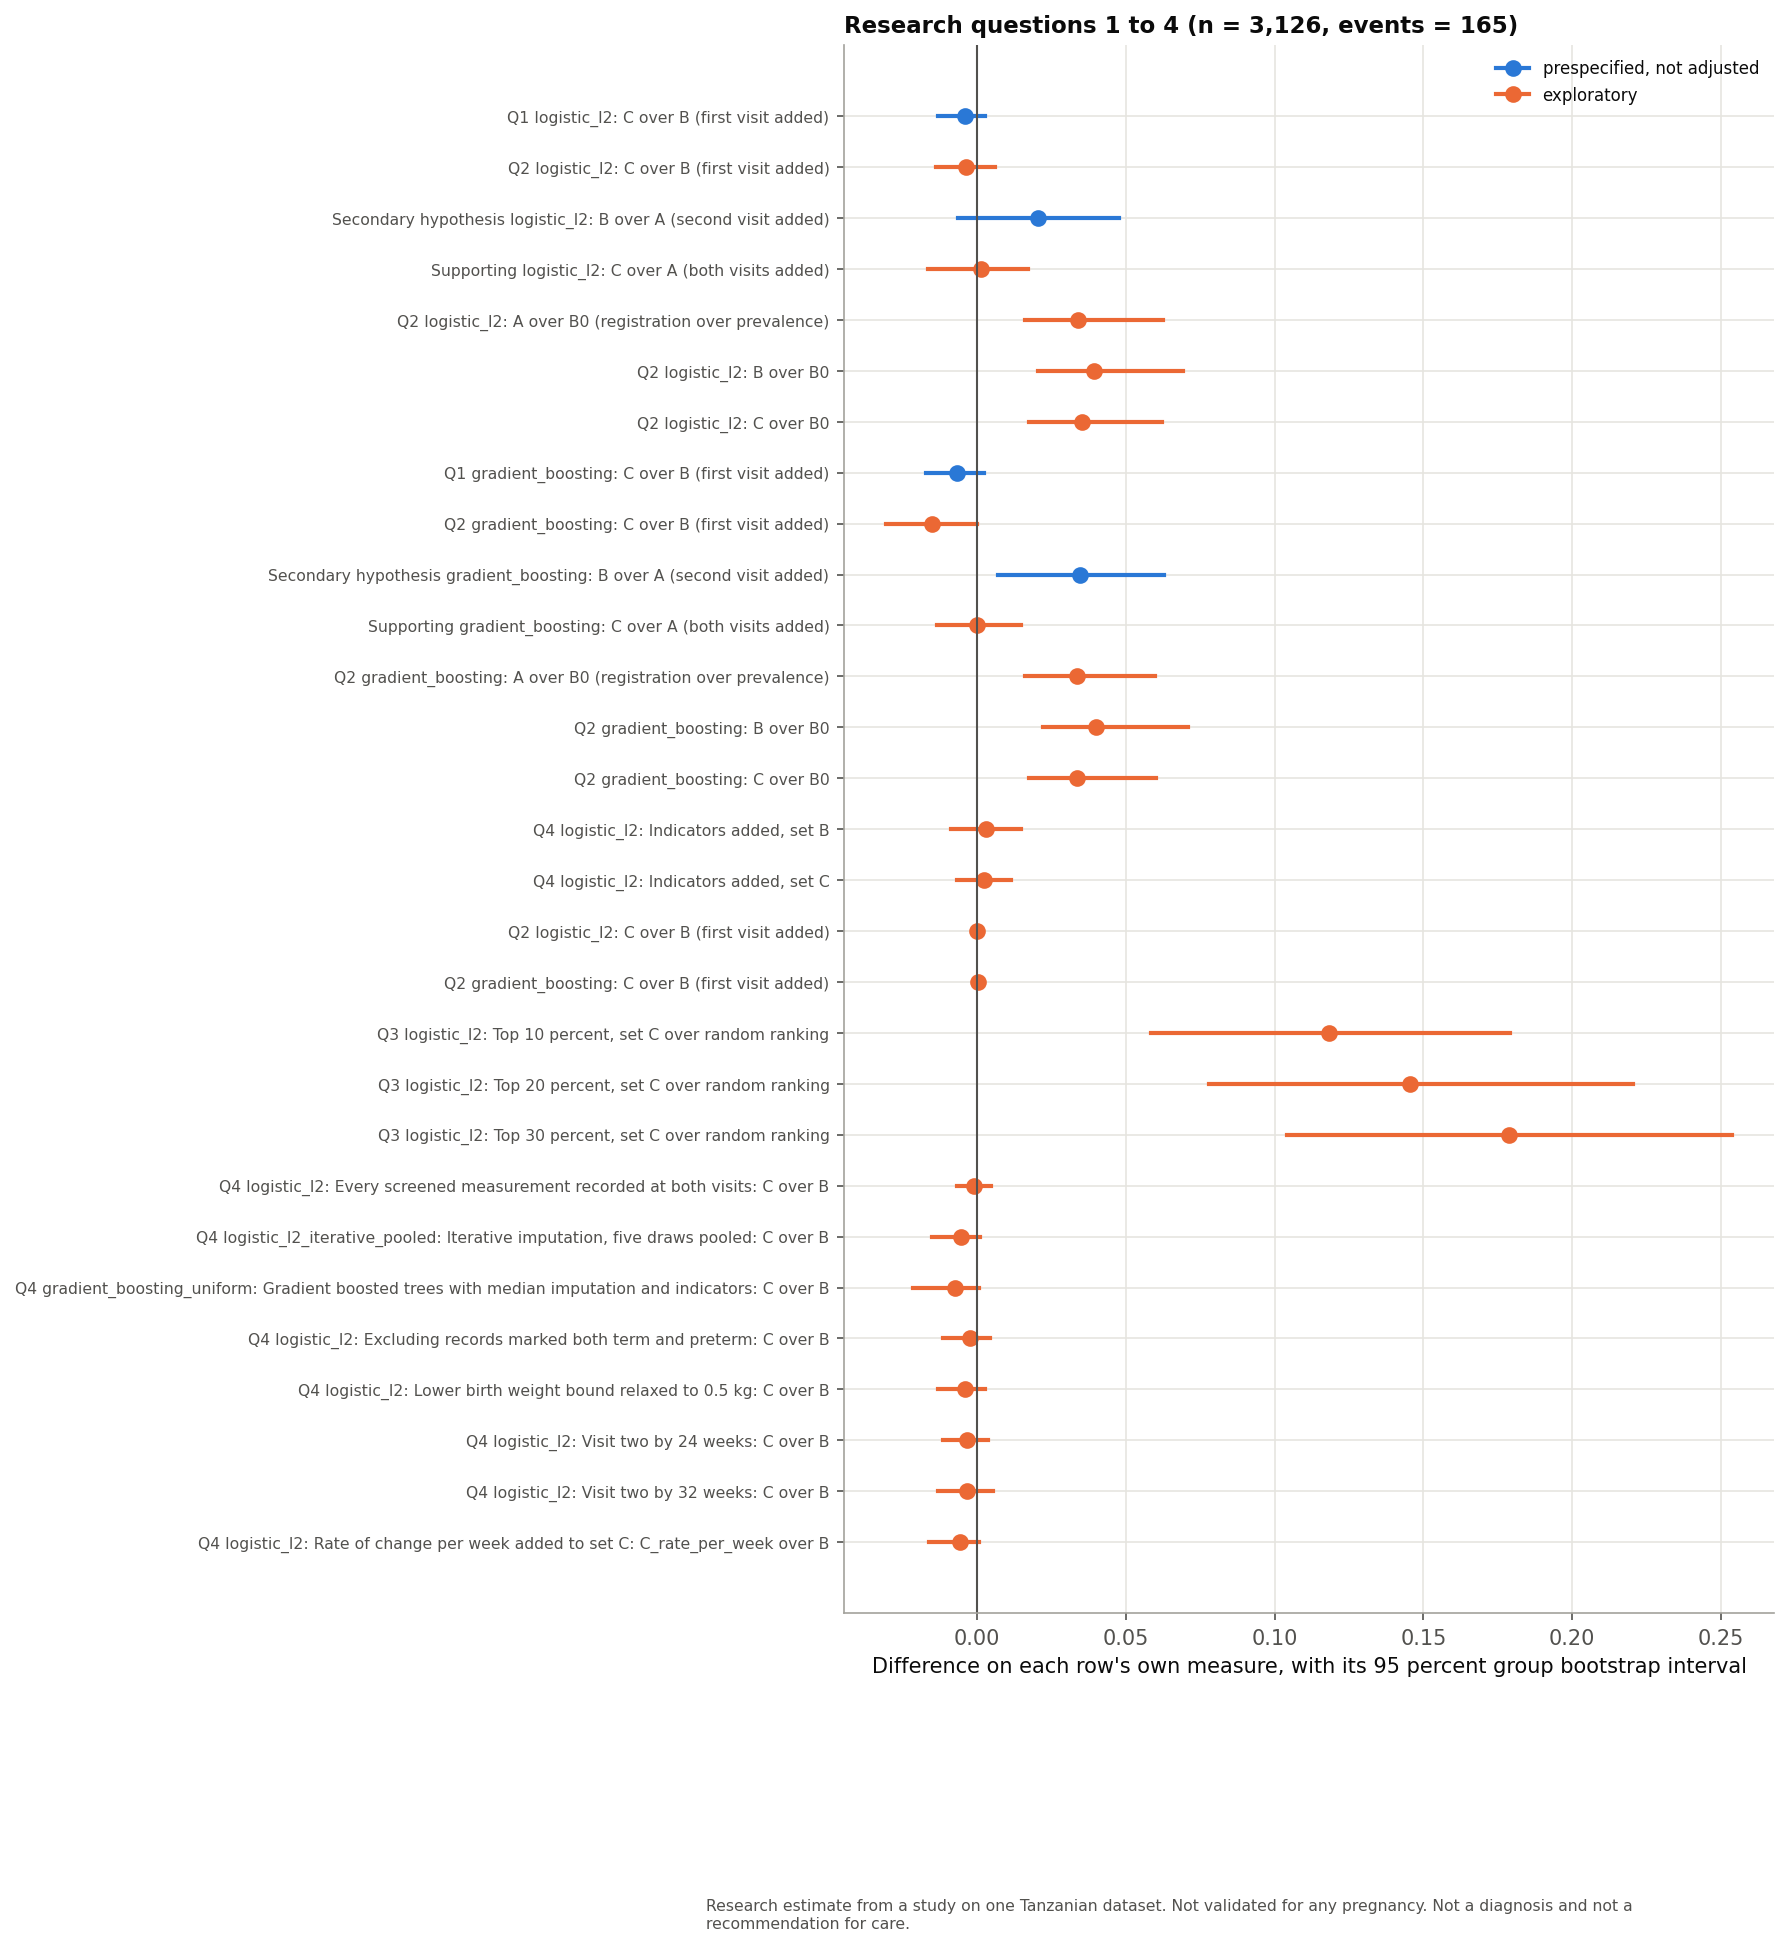

In [12]:
display(Image(filename=str(research / 'figures' / 'research_differences.png')))

The Stage 2 experiments were tested as their own exploratory family with a Holm adjustment when they ran (`outputs/tables/experiments_v2.csv`). Their average precision rows:

In [13]:
stage2 = table("experiments_v2")
stage2[stage2["role"] == "exploratory"][["comparison", "difference", "ci_low", "ci_high",
                                        "p_value", "p_holm"]].round(4)

,comparison,difference,ci_low,ci_high,p_value,p_holm
0,2.1a: logistic_elastic_net on A,-0.0005,-0.0075,0.0051,0.797,1.00
2,2.1a: logistic_elastic_net on B,-0.0019,-0.0085,0.0065,0.605,1.00
4,2.1a: logistic_elastic_net on C,-0.0025,-0.0089,0.0020,0.321,1.00
6,2.1b: gradient_boosting_search on A,0.0003,-0.0057,0.0118,0.843,1.00
8,2.1b: gradient_boosting_search on B,0.0002,-0.0107,0.0078,0.892,1.00
10,2.1b: gradient_boosting_search on C,0.0048,-0.0030,0.0173,0.255,1.00
12,2.2: logistic_l2_weighted on B,0.0004,-0.0051,0.0118,0.901,1.00
14,2.2: logistic_l2_weighted_platt on B,-0.0027,-0.0103,0.0088,0.569,1.00
16,2.2: gradient_boosting_weighted on B,-0.0025,-0.0185,0.0067,0.527,1.00
18,2.2: gradient_boosting_weighted_platt on B,-0.0033,-0.0176,0.0057,0.456,1.00


## 4. Held out records

This section is a template until the single held out evaluation runs. It then shows the confirmatory table from `outputs/tables/holdout_comparisons.csv`, read with 41 events: wide intervals are expected, and an interval that contains zero is not proof that two models are equal.

In [14]:
holdout = paths.tables / "holdout_comparisons.csv"
if holdout.exists():
    display(pd.read_csv(holdout))
    display(pd.read_csv(paths.tables / "holdout_result.csv"))
    display(pd.read_csv(paths.tables / "holdout_classification.csv"))
else:
    print("Not run: the held out evaluation waits for the supervisor's approval "
          "(docs/holdout_protocol.md).")

,comparison,metric,role,difference,ci_low,ci_high,bootstrap_se,detectable_difference,p_value,n,events,evaluated_at
0,C over B (first visit added),pr_auc,primary,0.0012,-0.0221,0.0185,0.0098,0.0274,0.707,782,41,2026-10-24T09:22:37+00:00
1,C over B (first visit added),roc_auc,descriptive,0.0236,0.0022,0.0437,0.0108,0.0303,0.033,782,41,2026-10-24T09:22:37+00:00
2,B over A (second visit added),roc_auc,secondary,0.0405,0.0008,0.0805,0.0205,0.0573,0.046,782,41,2026-10-24T09:22:37+00:00
3,B over A (second visit added),pr_auc,descriptive,0.0319,-0.0073,0.0735,0.0216,0.0606,0.127,782,41,2026-10-24T09:22:37+00:00


,model,metric,estimate,ci_low,ci_high,n,events,evaluated_at
0,C,pr_auc,0.1023,0.0532,0.1879,782,41,2026-10-24T09:22:37+00:00
1,C,roc_auc,0.5725,0.4752,0.6721,782,41,2026-10-24T09:22:37+00:00
2,C,brier,0.0495,0.0362,0.0634,782,41,2026-10-24T09:22:37+00:00
3,C,calibration_slope,0.4475,-0.4110,1.4021,782,41,2026-10-24T09:22:37+00:00
4,C,calibration_intercept,-0.0127,-0.3694,0.2656,782,41,2026-10-24T09:22:37+00:00
5,B,pr_auc,0.1011,0.0496,0.1884,782,41,2026-10-24T09:22:37+00:00
6,B,roc_auc,0.5489,0.4474,0.6531,782,41,2026-10-24T09:22:37+00:00
7,B,brier,0.0496,0.0363,0.0634,782,41,2026-10-24T09:22:37+00:00
8,B,calibration_slope,0.2588,-0.6809,1.3166,782,41,2026-10-24T09:22:37+00:00
9,B,calibration_intercept,-0.0137,-0.3701,0.2629,782,41,2026-10-24T09:22:37+00:00


,measure,estimate,ci_low,ci_high,detail,n,events,evaluated_at
0,flagged as likely,166.0000,NaN,NaN,"threshold 0.0688, events 41",782,41,2026-10-24T09:22:37+00:00
1,sensitivity,0.3415,0.2059,0.4865,at the fixed threshold,782,41,2026-10-24T09:22:37+00:00
2,specificity,0.7949,0.7643,0.8226,at the fixed threshold,782,41,2026-10-24T09:22:37+00:00
3,ppv,0.0843,0.0471,0.1312,at the fixed threshold,782,41,2026-10-24T09:22:37+00:00
4,npv,0.9562,0.9387,0.9714,at the fixed threshold,782,41,2026-10-24T09:22:37+00:00
5,retrieval in the top 10 percent,0.1463,0.0571,0.2727,random ranking gives 0.10,782,41,2026-10-24T09:22:37+00:00
6,retrieval in the top 20 percent,0.3415,0.1999,0.4737,random ranking gives 0.20,782,41,2026-10-24T09:22:37+00:00
7,retrieval in the top 30 percent,0.4390,0.2941,0.5946,random ranking gives 0.30,782,41,2026-10-24T09:22:37+00:00


## 5. Exports

`python -m antenatal research-results` writes `outputs/research/results_table.csv`, `outputs/research/research_questions.csv`, `outputs/research/figures/research_differences.png` and `docs/research_results.md`. The tests execute this notebook and fail on any error output.